# Image restoration with an autoencoder and a U-Net

The idea: take clean images, **damage them on purpose**, and train a network to undo the damage.

- input: the damaged image
- target: the original, clean image

We don't need any labels, because the clean image itself is the answer. So any collection of images can be used as training data.

We build two networks and compare them:

1. an **autoencoder**: the image is squeezed into a small "bottleneck" and then expanded back
2. a **U-Net**: the same network, but with extra "skip connections" that carry details past the bottleneck

## Setup

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import platform
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

# On a Mac this small model trains faster on the CPU than on the GPU,
# so we hide the GPU from TensorFlow.
if platform.system() == "Darwin":
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")

# Same random numbers every time, so the results can be repeated
keras.utils.set_random_seed(0)
print("Keras", keras.__version__)

Keras 3.12.0


## Data

We use the CIFAR-10 images: 60 000 small colour images of 32×32 pixels. Each pixel has 3 colour values (red, green, blue), so one image is an array of shape `(32, 32, 3)`.

The pixel values are 0–255. We divide them by 255 so they are between 0 and 1.

CIFAR-10 also has labels (cat, dog, ship, ...), but we don't need them, so we throw them away with `_`.

In [2]:
(x_train, _), (x_test, _) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

# Use the first 5000 training images for validation
x_val = x_train[:5000]
x_train = x_train[5000:]

print("training:  ", x_train.shape)
print("validation:", x_val.shape)
print("test:      ", x_test.shape)

training:   (45000, 32, 32, 3)
validation: (5000, 32, 32, 3)
test:       (10000, 32, 32, 3)


## Damaging the images

The function `damage` makes a damaged copy of a set of images. There are three kinds of damage:

- `"noise"`: random noise is added to every pixel (the network learns *denoising*)
- `"mask"`: an 8×8 square is painted black (the network learns *inpainting*, filling in a hole)
- `"lowres"`: every second pixel is thrown away and the rest are enlarged back to 32×32 (the network learns *super-resolution*)

Choose the kind of damage with `kind` and run the whole notebook again.

In [3]:
kind = "mask"    # "noise", "mask" or "lowres"

rng = np.random.default_rng(0)

def damage(images):
    if kind == "noise":
        noisy = images + rng.normal(0, 0.1, images.shape)
        return np.clip(noisy, 0, 1).astype("float32")

    if kind == "mask":
        damaged = images.copy()
        for img in damaged:
            row, col = rng.integers(0, 24, size=2)        # random corner of the square
            img[row:row + 8, col:col + 8] = 0              # paint it black
        return damaged

    if kind == "lowres":
        small = images[:, ::2, ::2]                        # every second pixel: 16×16
        return small.repeat(2, axis=1).repeat(2, axis=2)   # each pixel twice: 32×32

d_train = damage(x_train)
d_val = damage(x_val)
d_test = damage(x_test)

Let's look at a few test images. The top row is what the network gets, the bottom row is what it should produce.

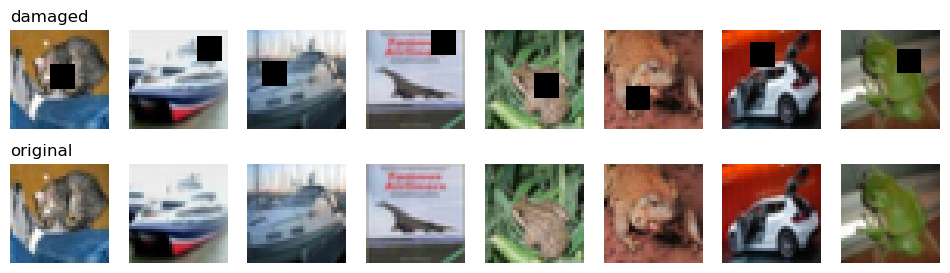

In [4]:
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for k in range(8):
    ax[0, k].imshow(d_test[k])
    ax[1, k].imshow(x_test[k])
    ax[0, k].axis("off")
    ax[1, k].axis("off")
ax[0, 0].set_title("damaged", loc="left")
ax[1, 0].set_title("original", loc="left")
plt.show()

## How do we measure the result?

The training loss is the **mean squared error (MSE)** between the network's output and the original image. A smaller MSE is better.

MSE numbers like 0.0015 are hard to read, so image people usually report **PSNR** (peak signal-to-noise ratio) instead. For images with values between 0 and 1:

$$\mathrm{PSNR} = 10 \log_{10} \frac{1}{\mathrm{MSE}} \ \text{dB}$$

A **larger** PSNR is better. Every +3 dB means the error has been cut in half.

As a starting point we compute the PSNR of the damaged images themselves. A network is useful only if it does better than this "do nothing" baseline.

In [5]:
def psnr(images, originals):
    mse = np.mean((images - originals) ** 2)
    return 10 * np.log10(1 / mse)

print(f"Damaged images (baseline): {psnr(d_test, x_test):.2f} dB")

Damaged images (baseline): 17.54 dB


---
# Part 1: Autoencoder

An autoencoder has two halves:

- the **encoder** makes the image smaller step by step: convolutions find features, and `MaxPooling2D` halves the width and height
- the **decoder** makes it bigger again: `UpSampling2D` doubles the width and height, and convolutions fill in the details

```
32×32×3   input image
   ↓ Conv2D 32 filters
32×32×32
   ↓ MaxPooling2D (halves the size)
16×16×32
   ↓ Conv2D 64 filters
16×16×64
   ↓ MaxPooling2D
8×8×64
   ↓ Conv2D 16 filters
8×8×16    BOTTLENECK: 8·8·16 = 1024 numbers (the image has 32·32·3 = 3072)
   ↓ UpSampling2D (doubles the size)
16×16×16
   ↓ Conv2D 64 filters
16×16×64
   ↓ UpSampling2D
32×32×64
   ↓ Conv2D 32 filters
32×32×32
   ↓ Conv2D 3 filters, size 1×1
32×32×3   output image
```

Everything the decoder knows about the image has to pass through the bottleneck, which is only a third of the size of the image. The network must learn what is important to keep.

A few details in the code:

- `padding="same"` keeps the width and height unchanged in a convolution
- the numbers in the bottleneck are not pixels. They are **features** the network has learned, something like "an edge going up to the right, dark on the left".
- the last layer has 3 filters (red, green, blue) and a **sigmoid** activation, so the output values are between 0 and 1, like the pixels

In [6]:
inputs = keras.Input(shape=(32, 32, 3))

# Encoder
x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)   # 32×32×32
x = layers.MaxPooling2D()(x)                                           # 16×16×32
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)        # 16×16×64
x = layers.MaxPooling2D()(x)                                           # 8×8×64
x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)        # 8×8×16  bottleneck

# Decoder
x = layers.UpSampling2D()(x)                                           # 16×16×16
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)        # 16×16×64
x = layers.UpSampling2D()(x)                                           # 32×32×64
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)        # 32×32×32
outputs = layers.Conv2D(3, 1, activation="sigmoid")(x)                 # 32×32×3

autoencoder = keras.Model(inputs, outputs)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 16)       │         9,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 3)      │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,467 (220.57 KB)

 Trainable params: 56,467 (220.57 KB)

 Non-trainable params: 0 (0.00 B)

### Why does a simple upscale work?

`UpSampling2D` has no weights and learns nothing: it just copies every pixel into a 2×2 block. On its own it would make the image blocky.

The learning happens in the `Conv2D` layer **after** each upscale. After the copy, the four pixels of a 2×2 block are identical, but a 3×3 convolution centred on each of them sees a slightly different neighbourhood: the top-left copy sees more of the blocks above and to the left, the bottom-right copy more of the blocks below and to the right. So the convolution can give them different values, and it learns how the image should change smoothly or sharply from block to block.

So the decoder is not "a simple upscale". It is **upscale + learned convolution**, twice.

### Training

The input is the damaged image `d_train`, the target is the original `x_train`. The validation data is used to check that the network also works on images it has not been trained on.

In [7]:
autoencoder.compile(optimizer="adam", loss="mse")

history_ae = autoencoder.fit(
    d_train, x_train,
    validation_data=(d_val, x_val),
    epochs=5,
    batch_size=128,
    verbose=2,
)

Epoch 1/5


352/352 - 49s - 138ms/step - loss: 0.0139 - val_loss: 0.0094


Epoch 2/5


352/352 - 47s - 134ms/step - loss: 0.0071 - val_loss: 0.0065


Epoch 3/5


352/352 - 47s - 134ms/step - loss: 0.0061 - val_loss: 0.0057


Epoch 4/5


352/352 - 48s - 136ms/step - loss: 0.0056 - val_loss: 0.0053


Epoch 5/5


352/352 - 47s - 134ms/step - loss: 0.0052 - val_loss: 0.0050


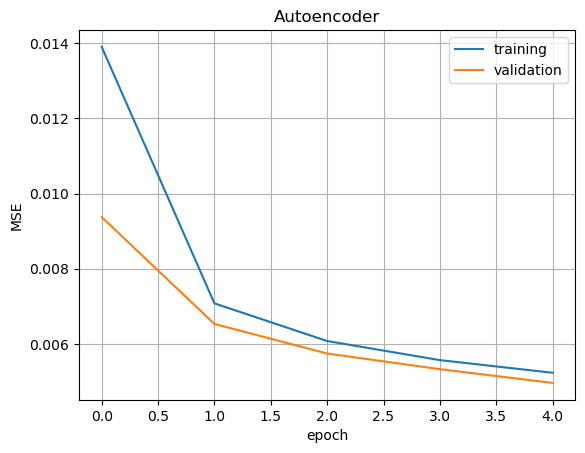

In [8]:
plt.plot(history_ae.history["loss"], label="training")
plt.plot(history_ae.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Autoencoder")
plt.grid()
plt.legend()
plt.show()

### Results on the test images

In [9]:
restored_ae = autoencoder.predict(d_test, verbose=0)

print(f"Damaged images (baseline): {psnr(d_test, x_test):.2f} dB")
print(f"Autoencoder:               {psnr(restored_ae, x_test):.2f} dB")

Damaged images (baseline): 17.54 dB
Autoencoder:               23.03 dB


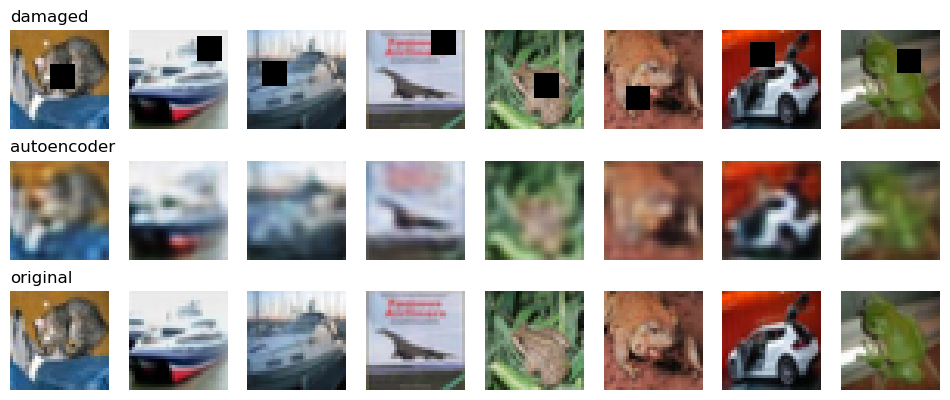

In [10]:
fig, ax = plt.subplots(3, 8, figsize=(12, 4.8))
for k in range(8):
    ax[0, k].imshow(d_test[k])
    ax[1, k].imshow(restored_ae[k])
    ax[2, k].imshow(x_test[k])
    ax[0, k].axis("off")
    ax[1, k].axis("off")
    ax[2, k].axis("off")
ax[0, 0].set_title("damaged", loc="left")
ax[1, 0].set_title("autoencoder", loc="left")
ax[2, 0].set_title("original", loc="left")
plt.show()

The autoencoder clearly beats the baseline, but its images are **blurry**. The small details didn't fit through the bottleneck, so the decoder can't bring them back. With `"mask"`, it also blurs the parts of the image that were never damaged at all.

---
# Part 2: U-Net

The U-Net fixes the blurriness with **skip connections**. They take the output of an encoder layer and give it straight to the decoder layer of the same size, past the bottleneck.

```
32×32×3   input image
   ↓ Conv2D 32 filters
32×32×32  ───────────────────────── skip ──────────────────────┐
   ↓ MaxPooling2D                                               │
16×16×32                                                        │
   ↓ Conv2D 64 filters                                          │
16×16×64  ──────────── skip ──────────┐                         │
   ↓ MaxPooling2D                      │                         │
8×8×64                                 │                         │
   ↓ Conv2D 16 filters                 │                         │
8×8×16    BOTTLENECK                   │                         │
   ↓ UpSampling2D                      │                         │
16×16×16                               │                         │
   ↓ Concatenate  ←────────────────────┘                         │
16×16×80  (16 + 64 channels side by side)                       │
   ↓ Conv2D 64 filters                                          │
16×16×64                                                        │
   ↓ UpSampling2D                                               │
32×32×64                                                        │
   ↓ Concatenate  ←─────────────────────────────────────────────┘
32×32×96  (64 + 32 channels side by side)
   ↓ Conv2D 32 filters
32×32×32
   ↓ Conv2D 3 filters, size 1×1
32×32×3   output image
```

(Drawn the usual way, with the encoder going down on the left and the decoder going up on the right, the picture looks like the letter U. That's where the name comes from.)

`Concatenate` puts two arrays of the same width and height side by side along the channel axis: 16×16×16 and 16×16×64 give 16×16×80.

Now the decoder gets two kinds of information:

- from the **skip connections**: the details of the input image at full resolution
- from the **bottleneck**: a summary of the whole image ("this is a horse, so the hole should be brown")

In code, the only difference to the autoencoder is that we must **save** the outputs of the encoder layers in their own variables (`skip1`, `skip2`) so we can use them again later.

In [11]:
inputs = keras.Input(shape=(32, 32, 3))

# Encoder
skip1 = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)   # 32×32×32, saved
x = layers.MaxPooling2D()(skip1)                                           # 16×16×32
skip2 = layers.Conv2D(64, 3, padding="same", activation="relu")(x)        # 16×16×64, saved
x = layers.MaxPooling2D()(skip2)                                           # 8×8×64
x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)            # 8×8×16  bottleneck

# Decoder
x = layers.UpSampling2D()(x)                                               # 16×16×16
x = layers.Concatenate()([x, skip2])                                       # 16×16×80
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)            # 16×16×64
x = layers.UpSampling2D()(x)                                               # 32×32×64
x = layers.Concatenate()([x, skip1])                                       # 32×32×96
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)            # 32×32×32
outputs = layers.Conv2D(3, 1, activation="sigmoid")(x)                     # 32×32×3

unet = keras.Model(inputs, outputs)
unet.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 64)  │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8, 16)  │      9,232 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 16, 16,    │          0 │ conv2d_8[0][0]    │
│ (UpSampling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 80)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │     46,144 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 32, 32,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 96)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32, 3) │         99 │ conv2d_10[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 102,547 (400.57 KB)

 Trainable params: 102,547 (400.57 KB)

 Non-trainable params: 0 (0.00 B)

The U-Net has more parameters than the autoencoder, because the convolutions after `Concatenate` get more channels as input.

### Training

Exactly the same as for the autoencoder.

In [12]:
unet.compile(optimizer="adam", loss="mse")

history_unet = unet.fit(
    d_train, x_train,
    validation_data=(d_val, x_val),
    epochs=5,
    batch_size=128,
    verbose=2,
)

Epoch 1/5


352/352 - 73s - 209ms/step - loss: 0.0069 - val_loss: 0.0023


Epoch 2/5


352/352 - 74s - 210ms/step - loss: 0.0019 - val_loss: 0.0018


Epoch 3/5


352/352 - 73s - 206ms/step - loss: 0.0016 - val_loss: 0.0015


Epoch 4/5


352/352 - 72s - 205ms/step - loss: 0.0014 - val_loss: 0.0013


Epoch 5/5


352/352 - 72s - 205ms/step - loss: 0.0013 - val_loss: 0.0015


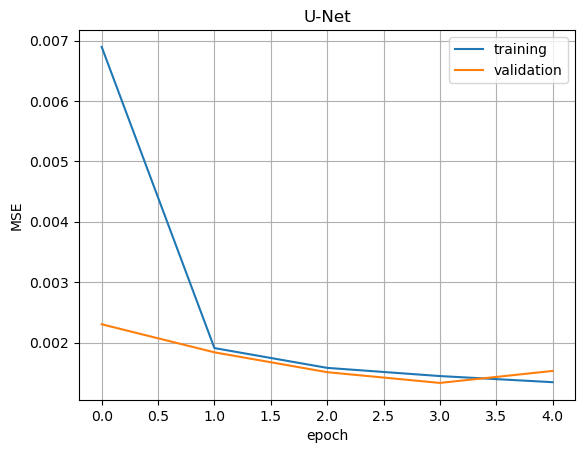

In [13]:
plt.plot(history_unet.history["loss"], label="training")
plt.plot(history_unet.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("U-Net")
plt.grid()
plt.legend()
plt.show()

### Results on the test images

In [14]:
restored_unet = unet.predict(d_test, verbose=0)

print(f"Damaged images (baseline): {psnr(d_test, x_test):.2f} dB")
print(f"U-Net:                     {psnr(restored_unet, x_test):.2f} dB")

Damaged images (baseline): 17.54 dB
U-Net:                     28.12 dB


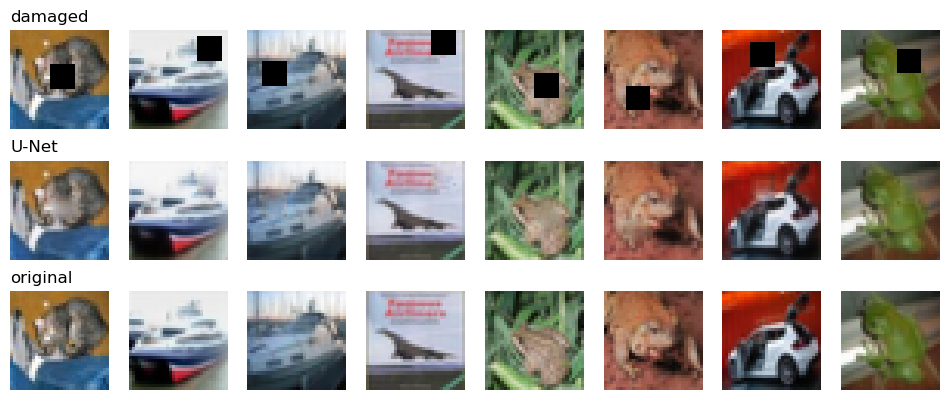

In [15]:
fig, ax = plt.subplots(3, 8, figsize=(12, 4.8))
for k in range(8):
    ax[0, k].imshow(d_test[k])
    ax[1, k].imshow(restored_unet[k])
    ax[2, k].imshow(x_test[k])
    ax[0, k].axis("off")
    ax[1, k].axis("off")
    ax[2, k].axis("off")
ax[0, 0].set_title("damaged", loc="left")
ax[1, 0].set_title("U-Net", loc="left")
ax[2, 0].set_title("original", loc="left")
plt.show()

---
# Comparison

In [16]:
print(f"Damaged images (baseline): {psnr(d_test, x_test):.2f} dB")
print(f"Autoencoder:               {psnr(restored_ae, x_test):.2f} dB")
print(f"U-Net:                     {psnr(restored_unet, x_test):.2f} dB")

Damaged images (baseline): 17.54 dB
Autoencoder:               23.03 dB
U-Net:                     28.12 dB


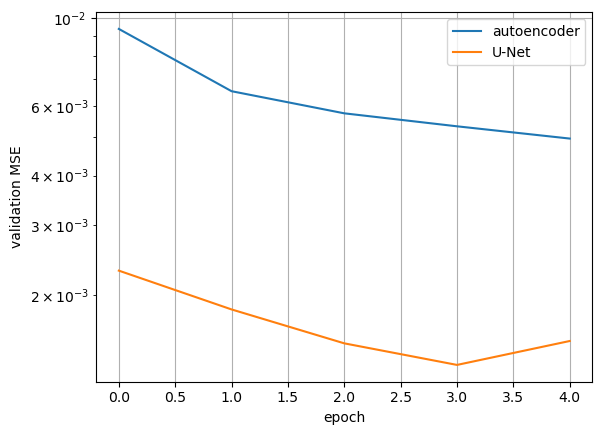

In [17]:
plt.plot(history_ae.history["val_loss"], label="autoencoder")
plt.plot(history_unet.history["val_loss"], label="U-Net")
plt.xlabel("epoch")
plt.ylabel("validation MSE")
plt.yscale("log")
plt.grid()
plt.legend()
plt.show()

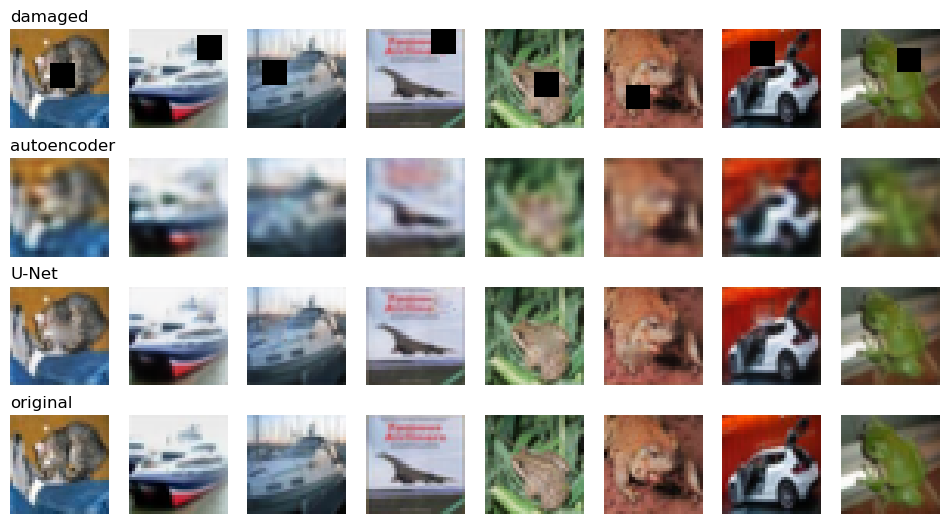

In [18]:
fig, ax = plt.subplots(4, 8, figsize=(12, 6.4))
for k in range(8):
    ax[0, k].imshow(d_test[k])
    ax[1, k].imshow(restored_ae[k])
    ax[2, k].imshow(restored_unet[k])
    ax[3, k].imshow(x_test[k])
    for r in range(4):
        ax[r, k].axis("off")
ax[0, 0].set_title("damaged", loc="left")
ax[1, 0].set_title("autoencoder", loc="left")
ax[2, 0].set_title("U-Net", loc="left")
ax[3, 0].set_title("original", loc="left")
plt.show()

The U-Net is clearly better. The skip connections let it copy the undamaged parts of the image almost as they are, so it doesn't have to squeeze them through the bottleneck. The bottleneck only needs to carry the information for repairing the damage.

## Things to try

- Other kinds of damage: set `kind = "noise"` or `"lowres"` and run the notebook again. Which kind is the hardest?
- Stronger noise (change `0.1`) or a bigger hole (change `8`; then `24` must be `32 - size`).
- In the autoencoder, remove the `Conv2D` line right after an `UpSampling2D`. What happens to the images?
- Make the bottleneck bigger or smaller (the `16` filters). How does it affect the autoencoder? And the U-Net?
- Train for more epochs.
- Use `loss="mae"` instead of `"mse"`. Which gives sharper images?